In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_22797/873884209.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2000-01-03,91.367516,93.134399,90.385914,93.134399,8164300
2000-01-04,87.794495,90.503717,87.725782,90.169972,8089800
2000-01-05,87.951500,88.913469,86.223881,87.912236,12177900
2000-01-06,86.538048,88.893893,86.538048,87.715970,6227200
2000-01-07,91.563850,91.563850,87.990819,88.147875,8066500


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

# Parameter sensitivity

In [ ]:
def backtest_sma(df, short_window, long_window):
    df = df.copy()

    df["sma_short"] = (
        df["Close"]
        .rolling(short_window)
        .mean()
    )

    df["sma_long"] = (
        df["Close"]
        .rolling(long_window)
        .mean()
    )

    df["signal"] = (
        df["sma_short"] > df["sma_long"]
    ).astype(int)

    df["returns"] = df["Close"].pct_change()

    df["strategy_returns"] = (
        df["signal"].shift(1)
        * df["returns"]
    )

    return (
        1 + df["strategy_returns"]
    ).prod() - 1


In [ ]:
short_windows = range(5, 55, 5)
long_windows = range(20, 220, 20)

results = []

for short_window in short_windows:
  for long_window in long_windows:

    if short_window >= long_window:
      continue

    total_return = backtest_sma(
        df,
        short_window,
        long_window
    )

    results.append({
        "short_window": short_window,
        "long_window": long_window,
        "total_return": total_return
    })


In [ ]:
results_df = pd.DataFrame(results)

In [ ]:
pivot = results_df.pivot(
    index="short_window",
    columns="long_window",
    values="total_return"
)


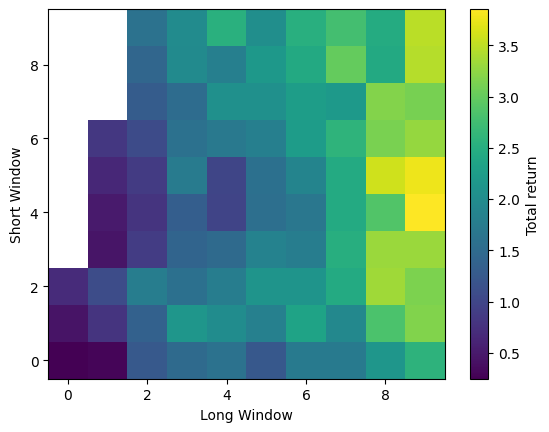

In [ ]:
plt.imshow(
    pivot,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Total return")
plt.xlabel("Long Window")
plt.ylabel("Short Window")
plt.show()

# Monte Carlo simulations

In [ ]:
fast = df['Close'].rolling(50).mean()
slow = df['Close'].rolling(200).mean()

signal = (fast > slow).astype(int)
df['Return'] = df['Close'].pct_change()
df['strategy_returns'] = signal.shift(1) * df['Return']

In [ ]:
strategy_returns = df['strategy_returns'].dropna()

In [ ]:
n_simulations = 1000

final_values = []

for _ in range(n_simulations):

    sampled_returns = np.random.choice(
        strategy_returns,
        size=len(strategy_returns),
        replace=True
    )

    final_value = (
        1 + sampled_returns
    ).prod()

    final_values.append(final_value)


In [ ]:
results = pd.Series(final_values)

print("Mean:", results.mean())
print("Median:", results.median())
print("5th percentile:", results.quantile(0.05))
print("95th percentile:", results.quantile(0.95))


Mean: 5.065710550578898
Median: 4.489119111747095
5th percentile: 1.9700437909938096
95th percentile: 10.105620700611217


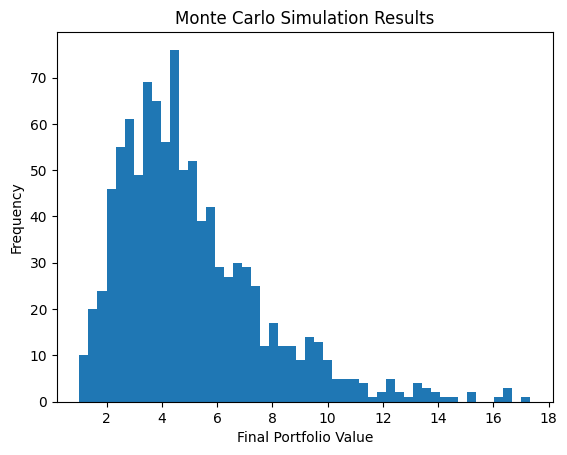

In [ ]:
import matplotlib.pyplot as plt

plt.hist(final_values, bins=50)

plt.xlabel("Final Portfolio Value")
plt.ylabel("Frequency")
plt.title("Monte Carlo Simulation Results")

plt.show()


# Stress testing

In [ ]:
# Random shock injection
def stress_test_random_shocks(df, shock_prob=0.05, shock_multiplier=3.0):
  df = df.copy()
  returns = df["Close"].pct_change().fillna(0)
  shock_mask = np.random.rand(len(returns)) < shock_prob
  stressed_returns = returns.copy()
  stressed_returns[shock_mask] *= shock_multiplier
  df["Close_stressed"] = (1 + stressed_returns).cumprod()
  sim_df = pd.DataFrame({
      "Close": df["Close_stressed"]
  })
  equity = backtest_sma(sim_df, short_window=10, long_window=100)
  return equity


In [ ]:
n_simulations = 1000
results = []
for _ in range(n_simulations):
  result = stress_test_random_shocks(
      df,
      shock_prob=0.05,
      shock_multiplier=3.0
  )
  results.append(result)
results = pd.Series(results)

In [ ]:
print("Mean:", results.mean())
print("Median:", results.median())
print("5th percentile:", results.quantile(0.05))
print("95th percentile:", results.quantile(0.95))


Mean: 1.9425246635374174
Median: 1.7993835491005508
5th percentile: 0.6914828538882412
95th percentile: 3.691743801395385


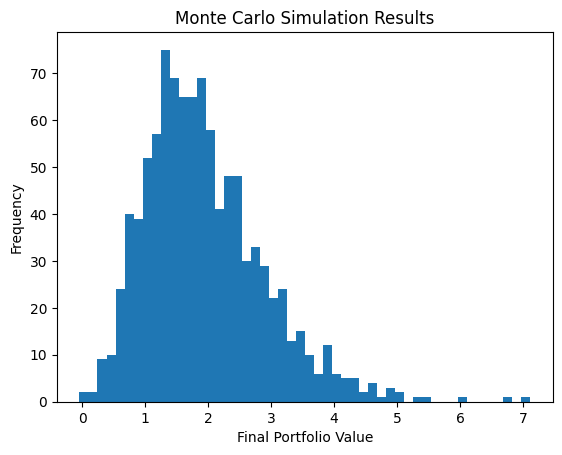

In [ ]:
import matplotlib.pyplot as plt

plt.hist(results, bins=50)

plt.xlabel("Final Portfolio Value")
plt.ylabel("Frequency")
plt.title("Monte Carlo Simulation Results")

plt.show()


# Model drift

In [ ]:
rolling_window = 252  # 1 trading year

rolling_sharpe = (
    df["strategy_returns"]
    .rolling(rolling_window)
    .mean()
    / df["strategy_returns"].rolling(rolling_window).std()
)

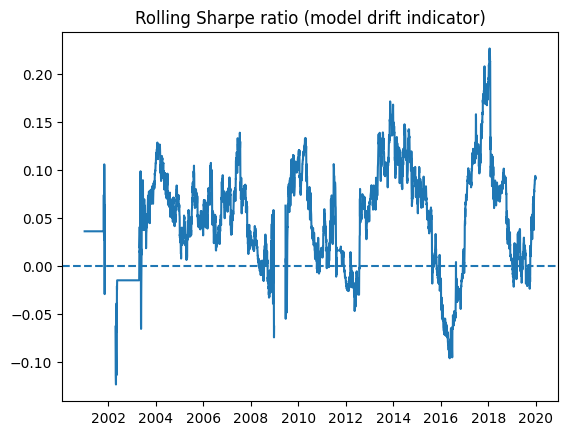

In [ ]:
# We see no degradation in Sharpe ratio
plt.plot(rolling_sharpe)
plt.axhline(0, linestyle="--")
plt.title("Rolling Sharpe ratio (model drift indicator)")
plt.show()

In [ ]:
# We see no degradation in signal-return correlation
df['signal'] = signal
rolling_corr = (
    df["signal"]
    .shift(1)
    .rolling(252)
    .corr(df["Return"])
)

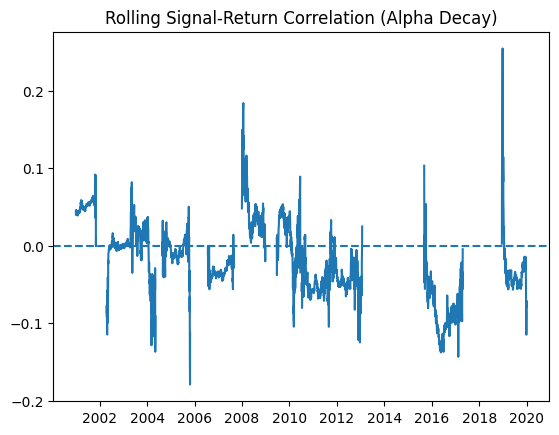

In [ ]:
plt.plot(rolling_corr)
plt.axhline(0, linestyle="--")

plt.title("Rolling Signal-Return Correlation (Alpha Decay)")
plt.show()

In [ ]:
# We see no degradation in returns
mid = len(df) // 2

early = df["strategy_returns"].iloc[:mid].sum()
late = df["strategy_returns"].iloc[mid:].sum()

print("Early period return:", early)
print("Late period return:", late)

Early period return: 0.7390755268338811
Late period return: 0.8828525326423649


# Regime detection

In [ ]:
# Volatility-based regimes
returns = df["Close"].pct_change()
rolling_vol = returns.rolling(window=20).std()

vol_threshold = rolling_vol.median()

df["vol_regime"] = np.where(
    rolling_vol > vol_threshold,
    1,
    0
)

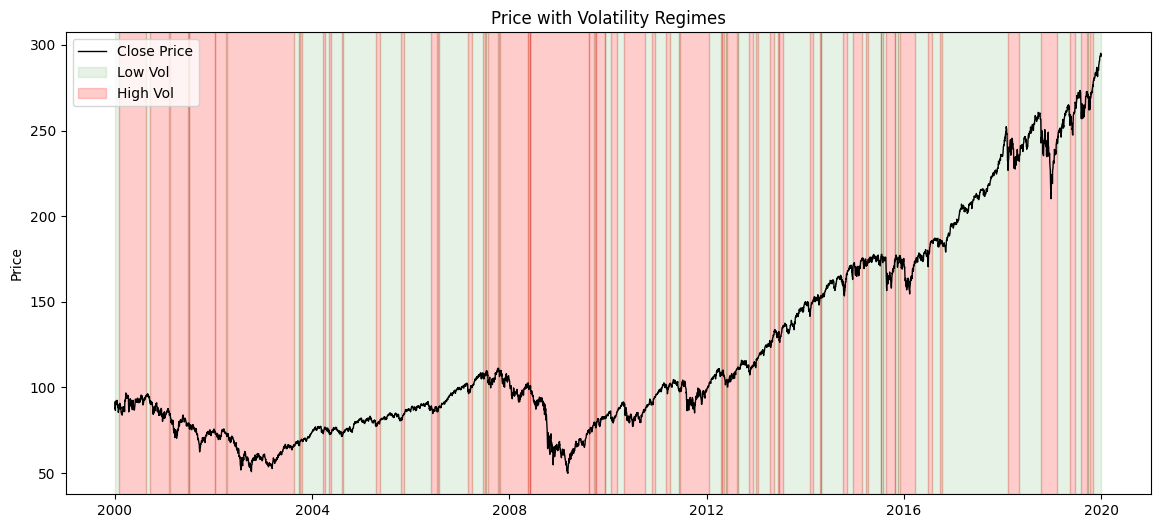

In [ ]:
# -----------------------------
# Plot price + regimes
# -----------------------------
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df["Close"], label="Close Price", color="black", linewidth=1)

# Highlight regimes
start_idx = df.index[0]
current_regime = df["vol_regime"].iloc[0]

for i in range(1, len(df)):
    if df["vol_regime"].iloc[i] != current_regime:
        end_idx = df.index[i]

        if current_regime == 1:
            ax.axvspan(start_idx, end_idx, color="red", alpha=0.2, label="High Vol" if "High Vol" not in ax.get_legend_handles_labels()[1] else "")
        else:
            ax.axvspan(start_idx, end_idx, color="green", alpha=0.1, label="Low Vol" if "Low Vol" not in ax.get_legend_handles_labels()[1] else "")

        start_idx = end_idx
        current_regime = df["vol_regime"].iloc[i]

# final segment
if current_regime == 1:
    ax.axvspan(start_idx, df.index[-1], color="red", alpha=0.2)
else:
    ax.axvspan(start_idx, df.index[-1], color="green", alpha=0.1)

ax.set_title("Price with Volatility Regimes")
ax.set_ylabel("Price")
ax.legend()
plt.show()

In [ ]:
# Trend-based regimes
ma = df["Close"].rolling(window=20).mean()

upper_band = ma * 1.01
lower_band = ma * 0.99

df["trend_regime"] = np.where(
    df["Close"] > upper_band,
    1,
    np.where(
        df["Close"] < lower_band,
        -1,
        0
    )
)


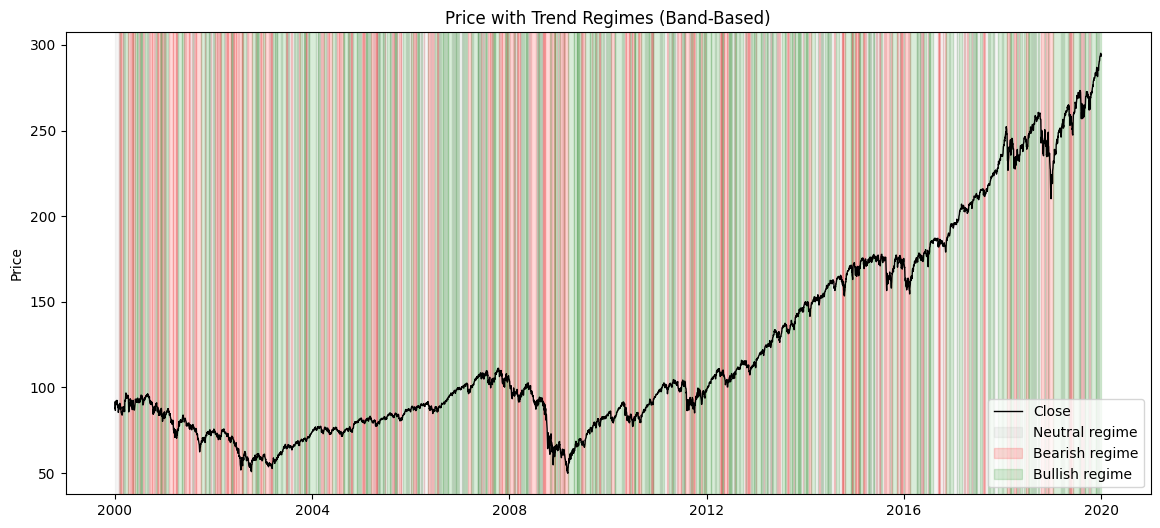

In [ ]:
# -----------------------------
# Plot price + regimes
# -----------------------------
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df["Close"], color="black", linewidth=1, label="Close")

# colors for regimes
colors = {
    1: ("green", 0.15),   # bullish
    0: ("gray", 0.08),    # neutral
    -1: ("red", 0.15)     # bearish
}

start_idx = df.index[0]
current_regime = df["trend_regime"].iloc[0]

for i in range(1, len(df)):
    if df["trend_regime"].iloc[i] != current_regime:
        end_idx = df.index[i]

        color, alpha = colors[current_regime]

        label = None
        if current_regime == 1:
            label = "Bullish regime"
        elif current_regime == 0:
            label = "Neutral regime"
        else:
            label = "Bearish regime"

        ax.axvspan(
            start_idx,
            end_idx,
            color=color,
            alpha=alpha,
            label=label if label not in ax.get_legend_handles_labels()[1] else ""
        )

        start_idx = end_idx
        current_regime = df["trend_regime"].iloc[i]

# final segment
color, alpha = colors[current_regime]

ax.axvspan(
    start_idx,
    df.index[-1],
    color=color,
    alpha=alpha
)

ax.set_title("Price with Trend Regimes (Band-Based)")
ax.set_ylabel("Price")
ax.legend()
plt.show()

In [ ]:
# Aggregated return-based regimes
rolling_return = df["Close"].pct_change().rolling(window=20).sum()

df["return_regime"] = np.where(
    rolling_return > 0,
    1,
    -1
)


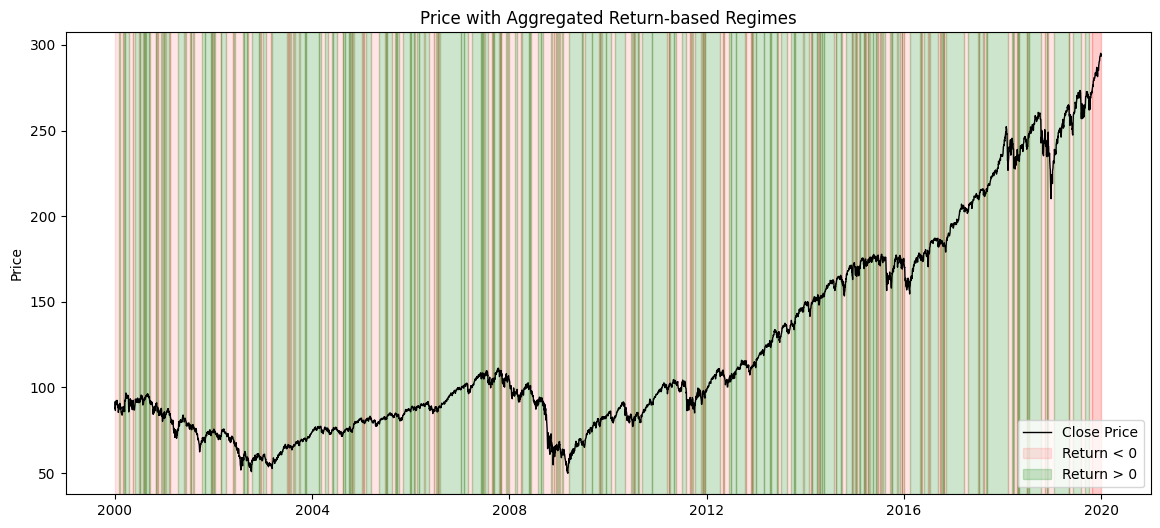

In [ ]:
# -----------------------------
# Plot price + regimes
# -----------------------------
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df["Close"], label="Close Price", color="black", linewidth=1)

# Highlight regimes
start_idx = df.index[0]
current_regime = df["return_regime"].iloc[0]

for i in range(1, len(df)):
    if df["return_regime"].iloc[i] != current_regime:
        end_idx = df.index[i]

        if current_regime == 1:
            ax.axvspan(start_idx, end_idx, color="green", alpha=0.2, label="Return > 0" if "Return > 0" not in ax.get_legend_handles_labels()[1] else "")
        else:
            ax.axvspan(start_idx, end_idx, color="red", alpha=0.1, label="Return < 0" if "Return < 0" not in ax.get_legend_handles_labels()[1] else "")

        start_idx = end_idx
        current_regime = df["return_regime"].iloc[i]

# final segment
if current_regime == 1:
    ax.axvspan(start_idx, df.index[-1], color="red", alpha=0.2)
else:
    ax.axvspan(start_idx, df.index[-1], color="green", alpha=0.1)

ax.set_title("Price with Aggregated Return-based Regimes")
ax.set_ylabel("Price")
ax.legend()
plt.show()